## All you need for loading opensim models

In [1]:
# Set the path to the parent directory of the directory containing this fil
import sys
sys.path.append('../../')
import os
os.chdir('../../')

In [2]:
%load_ext autoreload
%autoreload 2
from src.opensim import opensim_utils
import numpy as np
import pandas as pd

In [5]:
model = opensim_utils.get_model('/Users/markusgambietz/Downloads/tmp 15/tmpgocp9_dn/S03/Models/match_markers_but_ignore_physics.osim')
all_bodies = opensim_utils.get_bsip_dataframe_with_feet_and_HAT(model)
all_bodies['d_com'] = all_bodies['mass_center'].apply(lambda x: np.linalg.norm(x))

[info] Updating Model file from 40500 to latest format...
[info] Loaded model optimized_scale_and_markers from file /Users/markusgambietz/Downloads/tmp 15/tmpgocp9_dn/S03/Models/match_markers_but_ignore_physics.osim


In [8]:
all_bodies

,name,mass,mass_center,inertia,d_com
0,pelvis,10.027699,"[-0.0707, 0.0, 0.0]","[[0.0875305663, 0.0, 0.0], [0.0, 0.0741625712,...",0.070700
1,femur_r,7.919813,"[0.0, -0.17, 0.0]","[[0.1140111169, 0.0, 0.0], [0.0, 0.0298864093,...",0.170000
2,tibia_r,3.156805,"[0.0, -0.1867, 0.0]","[[0.0429138185, 0.0, 0.0], [0.0, 0.0043424697,...",0.186700
3,patella_r,0.071420,"[0.0018, 0.0264, 0.0]","[[2.377916782999631e-06, 0.0, 0.0], [0.0, 1.08...",0.026461
4,talus_r,0.085146,"[0.0, 0.0, 0.0]","[[0.0008514647, 0.0, 0.0], [0.0, 0.0008514647,...",0.000000
5,calcn_r,1.064331,"[0.1, 0.03, 0.0]","[[0.0011920505, 0.0, 0.0], [0.0, 0.0033207121,...",0.104403
6,toes_r,0.184427,"[0.0346, 0.006, -0.0175]","[[0.0005368485, 0.0, 0.0], [0.0, 0.0006219949,...",0.039235
7,femur_l,7.919813,"[0.0, -0.17, 0.0]","[[0.1140111169, 0.0, 0.0], [0.0, 0.0298864093,...",0.170000
8,tibia_l,3.156805,"[0.0, -0.1867, 0.0]","[[0.0429138185, 0.0, 0.0], [0.0, 0.0043424697,...",0.186700
9,patella_l,0.071420,"[0.0018, 0.0264, 0.0]","[[2.377916782999631e-06, 0.0, 0.0], [0.0, 1.08...",0.026461


In [6]:
b1 = all_bodies.iloc[13]
b2 = bsip.iloc[5]
print(f"Bodies: b1: {b1['name']}, b2: {b2['segment']}")
print(f"Mass: b1: {b1['mass']:.2f}, b2: {b2['mass']:.2f}")
#Create a nice looking .2f string for the mass center numpy array
print(f"Mass center: b1: {b1['mass_center']}, b2: {b2['com']}")
print(f"inertia: b1: {b1['inertia']}, b2: {b2['inertia']}")

NameError: name 'bsip' is not defined

In [15]:
# Check the bodyscan results
bsip = pd.read_pickle("/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/P03/bodyhull/bsip/SMPL_skin_loose.pkl")
bsip

,segment,mass,com,inertia
0,toes_r,0.013404,"[0.005316400405557399, -0.011285130062599628, ...","[[8.755284261660087e-07, -9.172491102418347e-0..."
1,calcn_r,0.516091,"[0.011817184508117702, 0.0024114553597432403, ...","[[0.001537436933329768, 0.00019893629066451937..."
2,tibia_r,2.728592,"[-0.010224432915151705, -0.15618730842749048, ...","[[0.03116119900655863, 0.0004070479274126184, ..."
3,femur_r,9.431697,"[-0.021587656856366603, -0.15206774665627926, ...","[[0.1481581628121463, 0.01842041525103369, -0...."
4,pelvis,13.271406,"[-0.00359678321090745, 0.01504781090880896, -0...","[[0.12956674032526655, 0.0017440276184366441, ..."
5,lumbar_body,20.330415,"[-0.0006547096314731978, 0.21948466931037794, ...","[[0.5170314711906012, 0.019219877748658337, 0...."
6,humerus_r,1.735752,"[-0.11892880364257583, -0.00822243209661759, -...","[[0.002551145529176176, -0.002860404221182183,..."
7,ulna_r,0.759904,"[-0.09524370385171976, 0.014364792449845646, -...","[[0.0003970780886143008, -0.000124646617689060..."
8,hand_r,0.200737,"[-0.05747585805689699, -0.010128215103475715, ...","[[7.709035453946445e-05, -0.000112201817458436..."
9,toes_l,0.008390,"[-0.007252468420585826, -0.007421792441556211,...","[[3.693079034276118e-07, -1.2126763217864776e-..."


## All you need for making an opensim model

In [3]:
import opensim
from scipy import signal

In [172]:
# Run a generic ID task
##
# @brief Butterworth zero-lag filtering function based on scipy
#
# @param    data    np-array:   array containing the signal that needs to be filtered along axis 0
# @param cutoff_freq:    float:  cutoff frequency of the filter
# @param nyq_freq:   float: nyquist frequency (=0.5*sampling rate)
# @param order:  int: filter order, gets doubled by using filtfilt
#
# @retval    np-array:      filtered input data
CUTOFF_FREQ = 6
def butter_lowpass_filter(data, cutoff_freq=CUTOFF_FREQ, nyq_freq=50, order=2):
    # set up filter
    w = float(cutoff_freq / (nyq_freq))
    sos = signal.butter(order, w, 'low', output='sos')
    # do the filtering
    y = signal.sosfiltfilt(sos, data, axis=0)
    return y

In [173]:
model_no_phys = "data/P03/gait/Models/match_markers_but_ignore_physics.osim"
model_w_phys = "data/P03/gait/Models/match_markers_and_physics.osim"
ik_file = "data/P03/gait/IK/Trial2 - last minute_segment_0_ik.mot"
marker_file = "data/P03/gait/MarkerData/Trial2 - last minute_segment_0.trc"
grf_file = "data/P03/gait/ID/Trial2 - last minute_segment_0_external_forces.xml"
def glob_path(path):
    return os.path.join(os.getcwd(), path)

In [174]:
# Perform ID task with model that ignores physics
import opensim
model = opensim.Model(model_no_phys)
model.initSystem()
id_tool = opensim.InverseDynamicsTool('data/P03/gait/ID/Trial2 - last minute_segment_0_id_setup.xml')
id_tool.setModel(model)
id_tool.setCoordinatesFileName(glob_path(ik_file))
id_tool.setExternalLoadsFileName(glob_path(grf_file))
id_tool.set_results_directory(glob_path("notebooks/opensim/"))
id_tool.setOutputGenForceFileName("ID_trial_2_0_no_phys.sto")
id_tool.setLowpassCutoffFrequency(-1)
# Find start and end times from the ik_file - for later
id_tool.setStartTime(0)
id_tool.setEndTime(20)
print(id_tool.getOutputGenForceFileName())
print(id_tool.getStartTime())
print(id_tool.getEndTime())
print(id_tool.getCoordinatesFileName())
print(id_tool.getLowpassCutoffFrequency())
id_tool.run()
a = 1

[info] Updating Model file from 40500 to latest format...
[info] Loaded model optimized_scale_and_markers from file data/P03/gait/Models/match_markers_but_ignore_physics.osim
ID_trial_2_0_no_phys.sto
0.0
20.0
/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/data/P03/gait/IK/Trial2 - last minute_segment_0_ik.mot
-1.0

               MODEL: optimized_scale_and_markers
         coordinates: 39
              forces: 97
           actuators: 97
             muscles: 80
            analyses: 0
              probes: 0
              bodies: 22
              joints: 22
         constraints: 2
             markers: 42
         controllers: 0
  contact geometries: 0
misc modelcomponents: 0
[info] Running tool Trial2 - last minute_segment_0...
[warning] Couldn't find file 'r_pelvis.vtp'.
[warning] Couldn't find file 'l_pelvis.vtp'.
[warning] Couldn't find file 'sacrum.vtp'.
[warning] Couldn't find file 'r_femur.vtp'.
[warning] Couldn't find file 'r_tibia.vtp'.
[warning] Couldn't find f

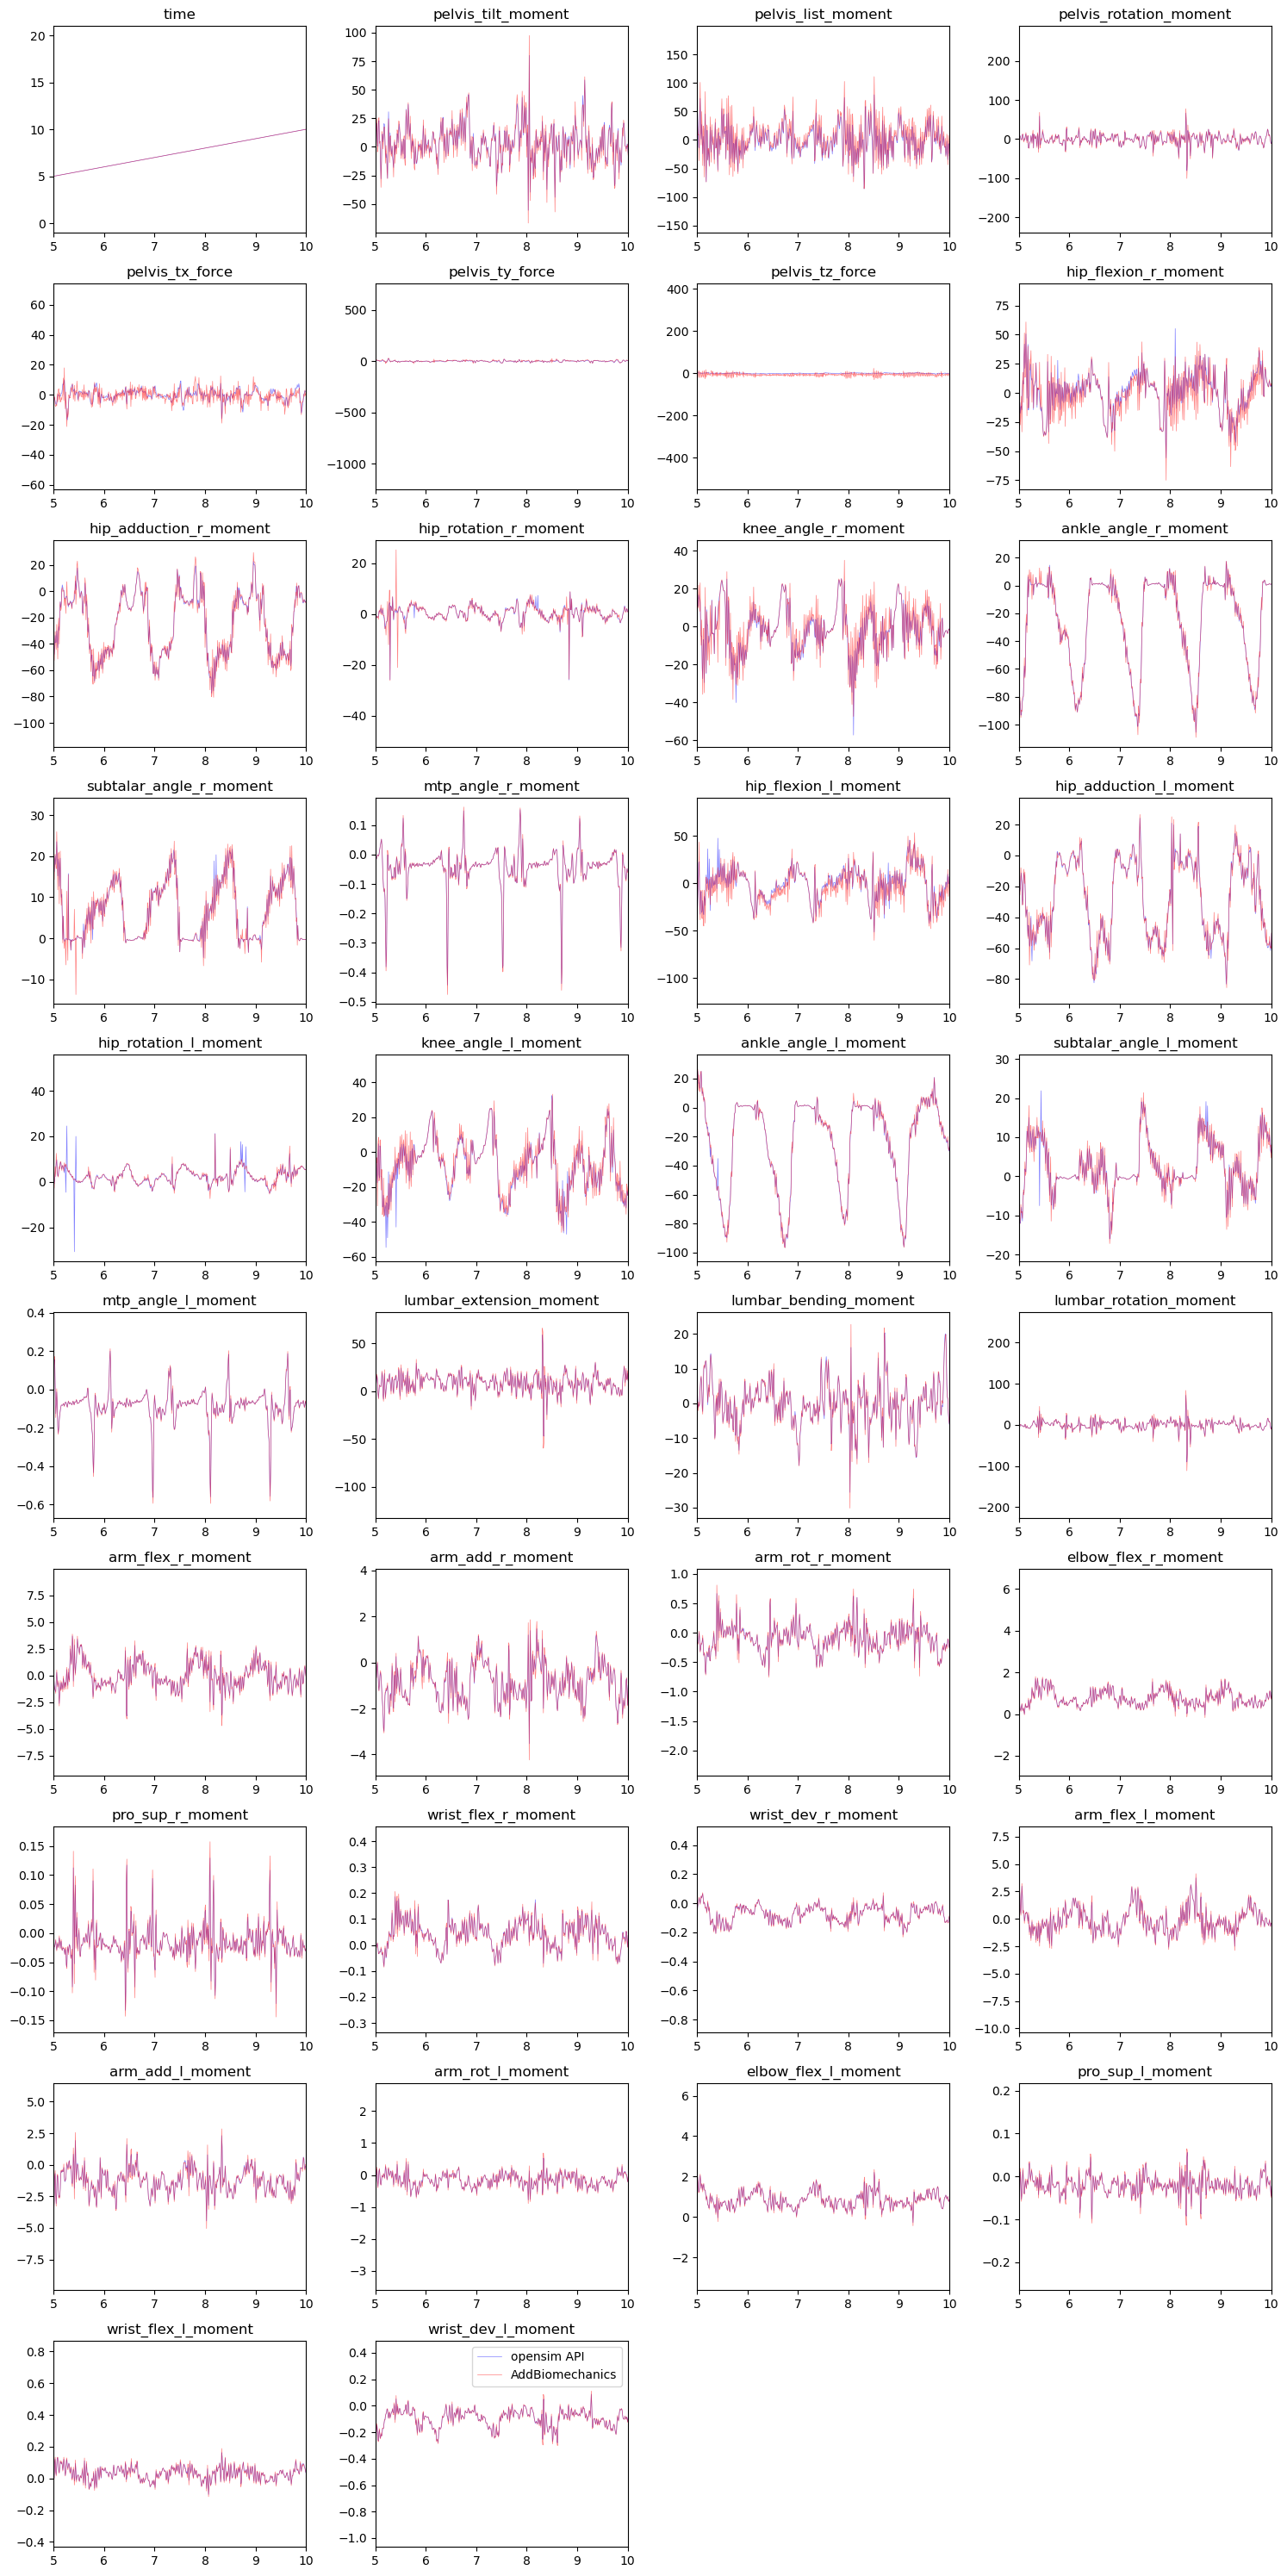

In [176]:
import pandas as pd
import matplotlib.pyplot as plt
a = pd.read_csv("notebooks/opensim/ID_trial_2_0_w_phys.sto", sep='\t', skiprows=6)
b = pd.read_csv("data/P03/gait/ID/Trial2 - last minute_segment_0_id.sto", sep='\t', skiprows=10)

fig = plt.figure(figsize=(15,30))
# Plot every column
idx = 0
for col_a in b.columns:
    ax = fig.add_subplot(10,4,idx+1)
    if col_a in a.columns:
        # Make the lines thinner
        ax.plot(a.time,b[col_a], label='opensim API', color='blue', alpha=0.5, linewidth=0.5)
        ax.plot(b.time,a[col_a], label='AddBiomechanics', color='red', alpha=0.5, linewidth=0.5)
    ax.set_title(col_a)
    idx += 1
    ax.set_xlim([5,10])
plt.tight_layout()
plt.legend()

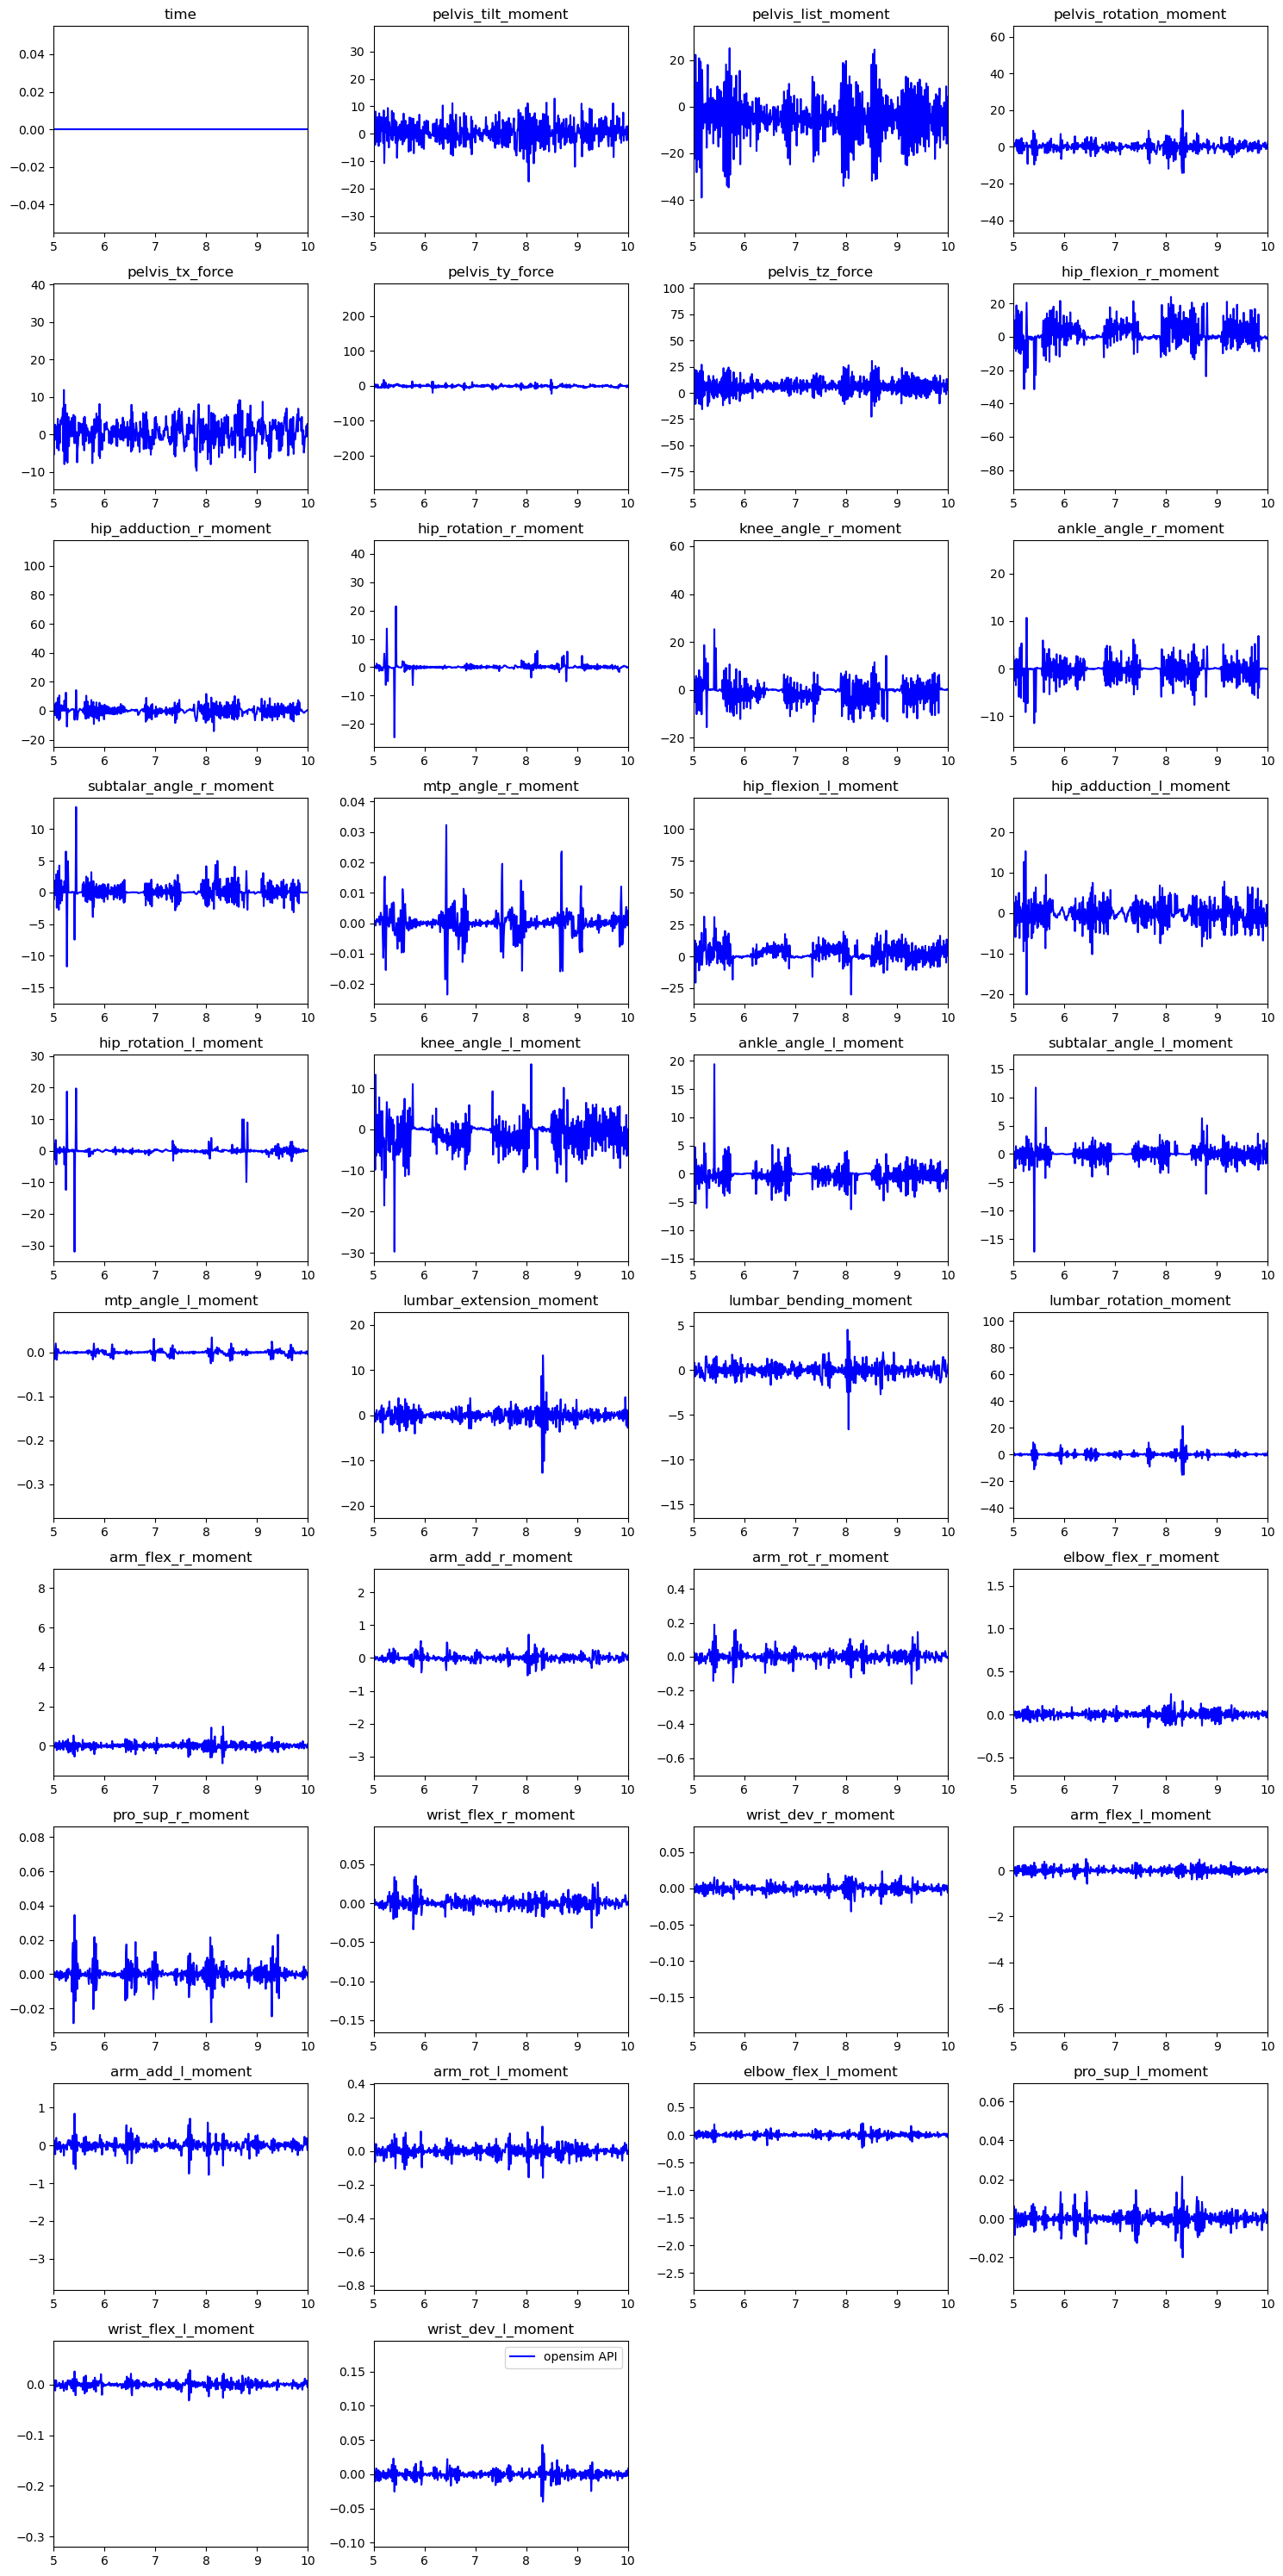

In [169]:
import pandas as pd
import matplotlib.pyplot as plt
a = pd.read_csv("notebooks/opensim/ID_trial_2_0_w_phys.sto", sep='\t', skiprows=6)
b = pd.read_csv("data/P03/gait/ID/Trial2 - last minute_segment_0_id.sto", sep='\t', skiprows=10)

fig = plt.figure(figsize=(15,30))
# Plot every column
idx = 0
for col_a in b.columns:
    ax = fig.add_subplot(10,4,idx+1)
    if col_a in a.columns:
        # Make the lines thinner
        ax.plot(a.time,b[col_a]-a[col_a], label='opensim API', color='blue')
    ax.set_title(col_a)
    idx += 1
    ax.set_xlim([5,10])
plt.tight_layout()
plt.legend()

# Important to do: Clean up GRF data!

grf = "data/P03/gait/ID/Trial2 - last minute_segment_0_grf.mot"

In [12]:
import pandas as pd
import numpy as np
import os
os.chdir('/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/')

In [4]:
for part in ['P01','P02','P03','P04','P05','P06']:
    p_mass = []
    for trial in range(1,7):
        grf = pd.read_csv(f'data/{part}/gait/Trial{trial}.mot', sep='\t', skiprows=5)
        # Get means for all
        grf = grf.iloc[1000:-1000]
        mean_x = grf['ground_force_vx'].mean() + grf['1_ground_force_vx'].mean()
        mean_y = grf['ground_force_vy'].mean() + grf['1_ground_force_vy'].mean()
        if (part != 'P01') or (trial < 3):
            p_mass.append(mean_y)
        mean_z = grf['ground_force_vz'].mean() + grf['1_ground_force_vz'].mean()
        print(f'{part} - {trial}: {mean_x:.2f}, {mean_y:.2f}, {mean_z:.2f} [N] (x,y,z)')
    print(f'{part}: {np.mean(p_mass)/9.81:.2f} [kg]')
        

P01 - 1: 13.94, 709.18, -0.68 [N] (x,y,z)
P01 - 2: 7.67, 709.54, 0.21 [N] (x,y,z)


FileNotFoundError: [Errno 2] No such file or directory: 'data/P01/gait/Trial3.mot'

In [6]:
os.getcwd()

'/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins'

In [ ]:
# ID pipelines to test
import subprocess
import pandas as pd
from src.opensim import opensim_utils#
# SMPL @ body, InsideHumans, HIT @ scan
print(os.getcwd())
os.environ["PYTHONPATH"] = os.getcwd()
sys.path.append(os.getcwd())
pipelines = [['HIT', 'body']]#, ['InsideHumans', 'skin']] #['HIT', 'scan']]
participants = ['P01','P02','P03','P04','P05','P06']
mass_list = [72.31,73.35,64.49, 89.36, 87.63,44.91]
gender_list = ['female','male','female', 'male', 'male','female']
hull = 'loose'
trial = 1
# Shod variation
unshod_mass = [72.31,72.2, 64, 88.5, 86.5, 44.0]
unshod_ = False

def glob_path(path):
    return os.path.join(os.getcwd(), path)

# Create the bsip dataframes
for participant, mass, gender, unshod in zip(participants, mass_list, gender_list, unshod_mass):
    for pipeline in pipelines:
        print(f"Participant: {participant}, Pipeline: {pipeline}")
        name, model = pipeline
        model_c = f"--model {model}"
        scan_c = f"--pipeline {name}"
        input_path = f"--input_path results/{participant}/bodyhull"
        output_path = f"--output_path results/{participant}/bodyhull/bsip/{name}"
        mass_c = f"--mass {unshod if unshod_ else mass}"
        gender_c = f"--gender={gender}"
        hull_c = f"--hull={hull}"
        extra_commans = f"--debug=True --use_skel=True"
        skel_c = "_w_skel"
        # 
        command = f"python src/bodyscan/estimate_bsip.py {model_c} {scan_c} {input_path} {output_path} {mass_c} {gender_c} {hull_c} {extra_commans}"
        print(command)
        subprocess.run(command, shell=True)
        
        opensim_model = f"results/{participant}/gait/addB-ignore_phys/Models/match_markers_but_ignore_physics.osim"
        opensim_model = opensim_utils.get_model(opensim_model)

        hull_bsip = pd.read_pickle(f"results/{participant}/bodyhull/bsip/{name}/{name}_{model}_{hull}{skel_c}.pkl")
        new_hull_bsip, osim_model = opensim_utils.hull_bsip_to_opensim(hull_bsip, opensim_model, extra_shoe_weight=(mass-unshod) if unshod_ else 0, arms_from_hull=False)
        os.makedirs(f"results/{participant}/bodyhull/osim_models", exist_ok=True)

        for trial in range(1,7):
            if (participant == 'P01' and trial > 2) or (participant == 'P06' and trial == 5):
                continue
            c0 = "python src/opensim/inverse_dynamics.py"
            c1 = f"--ik_path=results/{participant}/gait/addB-ignore_phys/IK/Trial{trial}.mot"
            c2 = f"--osim_file="+glob_path(f"results/{participant}/bodyhull/osim_models/{name}_{model}{skel_c}.osim")
            c3 = f"--output_file=results/{participant}/gait/ID_results/Trial{trial}_{name}_{model}.sto"
            c4 = f"--mot_path=data/{participant}/gait/Trial{trial}.mot --lowpass_f=15"

            subprocess.run(f"{c0} {c1.replace(f'Trial{trial}.mot','')} --concat_ik=True", shell=True)
            subprocess.run(f"{c0} {c1} {c2} {c3} {c4} > /dev/null 2>&1", shell=True)

            # Load the result file 
            res = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_{name}_{model}.sto", sep='\t', skiprows=6)
            print(f"Participant: {participant}, Pipeline: {pipeline}, MAE-Y: {res['pelvis_ty_force'].abs().mean()}")
        
            # Finally, run standard ID
            c2 = f"--osim_file=results/{participant}/gait/addB-ignore_phys/Models/match_markers_but_ignore_physics.osim"
            c3 = f"--output_file=results/{participant}/gait/ID_results/Trial{trial}_ignore_physics.sto"
            subprocess.run(f"{c0} {c1} {c2} {c3} {c4} > /dev/null 2>&1", shell=True)


/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins
Participant: P01, Pipeline: ['HIT', 'body']
python src/bodyscan/estimate_bsip.py --model body --pipeline HIT --input_path results/P01/bodyhull --output_path results/P01/bodyhull/bsip/HIT --mass 72.31 --gender=female --hull=loose --debug=True --use_skel=True
Could not repair mesh, fallback to convex hull
True
Meshes of result: dict_keys(['all', 'AT', 'BT', 'LT', 'skel']) MOI: dict_keys(['all', 'AT', 'BT', 'LT', 'skel'])
Mesh name: all
Volume: (new | old | diff) [L]: 71.43 | 71.43 | -0.00
Mesh name: AT
Volume: (new | old | diff) [L]: 27.94 | 27.76 | 0.17
Mesh name: BT
Volume: (new | old | diff) [L]: 2.13 | 2.13 | 0.00
Mesh name: LT
Volume: (new | old | diff) [L]: 38.77 | 38.77 | -0.00
Mesh name: skel
Volume: (new | old | diff) [L]: 6.49 | 6.59 | -0.10
Total mass: [73.32437589], Adjusting to 72.31
BSIPs estimated and saved to  {'results/P01/bodyhull/bsip/HIT/HIT_body_loose_w_skel.pkl'}
[info] Updating Model file from 40500 to la

KeyboardInterrupt: 

In [371]:
for col in pd.read_csv("data/P06/gait/Trial0.mot", sep='\t', skiprows=5).columns:
    if col in ['ground_force_vx', 'ground_force_vz', '1_ground_force_vx', '1_ground_force_vz']: print(col)


ground_force_vx
ground_force_vz
1_ground_force_vx
1_ground_force_vz


In [42]:
collfunc = lambda x: np.mean(np.abs(x))
pipelines = [['HIT', 'body']]#, ['InsideHumans', 'skin']] #['HIT', 'scan']]
participants = ['P01','P02','P03','P04','P05','P06']
mass_list = [72.31,73.35,64.49, 89.36, 87.63,44.91]
result_df = pd.DataFrame(columns=['participant', 'trial','pipeline', 'dimension', 'value','value_rel'])
for participant,mass in zip(participants, mass_list):
    for trial in range(1,7):
        if participant == "P03" or (participant == 'P06' and trial == 5) or (participant == 'P01' and trial > 2) or (participant == 'P03' and trial == 2):
            continue
        for pipeline in pipelines:
            name, model = pipeline
            name2 = name+model
            id1 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_{name}_{model}.sto", sep='\t', skiprows=6)
            id2 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_ignore_physics.sto", sep='\t', skiprows=6)
            for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force', 'pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']:
                result_df.loc[len(result_df)] = [participant, trial, name, dim, collfunc(id1[dim])/mass/9.81, (collfunc(id2[dim])-collfunc(id1[dim]))/collfunc(id2[dim])]
            result_df.loc[len(result_df)] = [participant, trial, name, 'f_norm', np.mean(np.linalg.norm([id1['pelvis_tx_force'], id1['pelvis_ty_force'], id1['pelvis_tz_force']], axis=0))/mass/9.81, 0]
            result_df.loc[len(result_df)] = [participant, trial, name, 'm_norm', np.mean(np.linalg.norm([id1['pelvis_tilt_moment'], id1['pelvis_list_moment'], id1['pelvis_rotation_moment']], axis=0))/mass/9.81, 0]
        for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force', 'pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']:
            result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', dim, collfunc(id2[dim])/mass/9.81, 0]
        result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', 'f_norm', np.mean(np.linalg.norm([id2[dim] for dim in ['pelvis_tx_force', 'pelvis_ty_force', 'pelvis_tz_force']], axis=0))/mass/9.81, 0]
        result_df.loc[len(result_df)] = [participant, trial, 'addB-IK', 'm_norm', np.mean(np.linalg.norm([id2[dim] for dim in ['pelvis_tilt_moment', 'pelvis_list_moment', 'pelvis_rotation_moment']], axis=0))/mass/9.81, 0]
result_df

,participant,trial,pipeline,dimension,value,value_rel
0,P01,1,HIT,pelvis_tx_force,0.045513,0.279692
1,P01,1,HIT,pelvis_ty_force,0.037733,0.065782
2,P01,1,HIT,pelvis_tz_force,0.039769,-0.060475
3,P01,1,HIT,pelvis_tilt_moment,0.032066,0.321517
4,P01,1,HIT,pelvis_list_moment,0.033561,-0.174727
...,...,...,...,...,...,...
395,P06,6,addB-IK,pelvis_tilt_moment,0.023650,0.000000
396,P06,6,addB-IK,pelvis_list_moment,0.016451,0.000000
397,P06,6,addB-IK,pelvis_rotation_moment,0.017840,0.000000
398,P06,6,addB-IK,f_norm,0.068838,0.000000


([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'pelvis_tx_force'),
  Text(1, 0, 'pelvis_ty_force'),
  Text(2, 0, 'pelvis_tz_force'),
  Text(3, 0, 'pelvis_tilt_moment'),
  Text(4, 0, 'pelvis_list_moment'),
  Text(5, 0, 'pelvis_rotation_moment'),
  Text(6, 0, 'f_norm'),
  Text(7, 0, 'm_norm')])

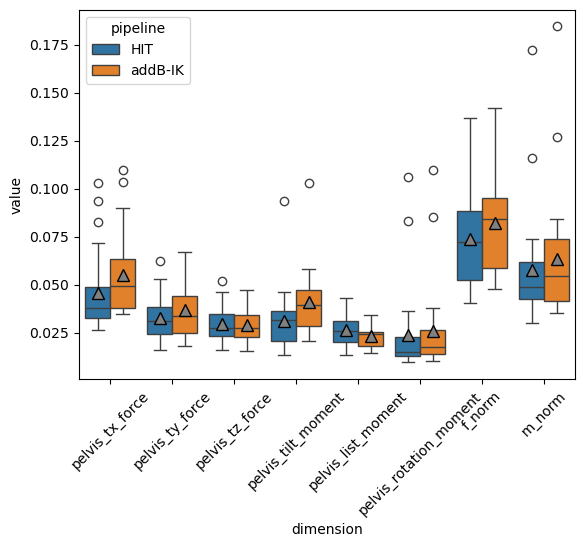

In [43]:
import seaborn as sns
sns.boxplot(x='dimension', y='value', data=result_df, hue='pipeline',showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
# Make the x labels vertical
plt.xticks(rotation=45)


In [105]:
result_df[result_df.value>0.08]

,participant,trial,pipeline,dimension,value,value_rel
15,P01,1,addB-IK,m_norm,0.081459,0.000000
110,P02,5,addB-IK,f_norm,0.083701,0.000000
197,P04,5,HIT,pelvis_rotation_moment,0.083860,0.024803
199,P04,5,HIT,m_norm,0.127704,0.000000
205,P04,5,addB-IK,pelvis_rotation_moment,0.085993,0.000000
206,P04,5,addB-IK,f_norm,0.085112,0.000000
207,P04,5,addB-IK,m_norm,0.138494,0.000000
291,P05,5,HIT,pelvis_tilt_moment,0.083441,0.101544
293,P05,5,HIT,pelvis_rotation_moment,0.106251,0.029937
295,P05,5,HIT,m_norm,0.170391,0.000000


([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'pelvis_tx_force'),
  Text(1, 0, 'pelvis_ty_force'),
  Text(2, 0, 'pelvis_tz_force'),
  Text(3, 0, 'pelvis_tilt_moment'),
  Text(4, 0, 'pelvis_list_moment'),
  Text(5, 0, 'pelvis_rotation_moment'),
  Text(6, 0, 'f_norm'),
  Text(7, 0, 'm_norm')])

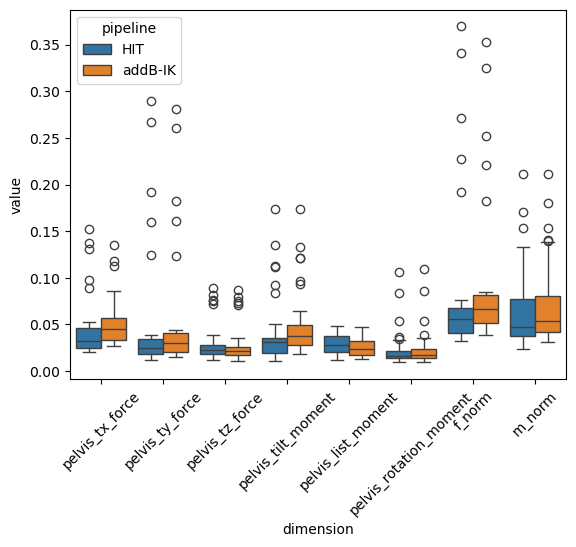

In [98]:
import seaborn as sns
sns.boxplot(x='dimension', y='value', data=result_df, hue='pipeline')
# Make the x labels vertical
plt.xticks(rotation=45)


In [112]:
result_df[['dimension','value','pipeline']].groupby(['dimension','pipeline']).mean()

value
dimension              pipeline          
f_norm                 HIT       0.073716
                       addB-IK   0.082009
m_norm                 HIT       0.057415
                       addB-IK   0.063220
pelvis_list_moment     HIT       0.026568
                       addB-IK   0.023016
pelvis_rotation_moment HIT       0.023987
                       addB-IK   0.025617
pelvis_tilt_moment     HIT       0.031246
                       addB-IK   0.040862
pelvis_tx_force        HIT       0.045747
                       addB-IK   0.054888
pelvis_ty_force        HIT       0.032740
                       addB-IK   0.036675
pelvis_tz_force        HIT       0.029605
                       addB-IK   0.028994

In [30]:
result_df[['dimension','value','pipeline']].groupby(['dimension','pipeline']).mean()

value
dimension              pipeline          
f_norm                 HIT       0.088963
                       addB-IK   0.093913
m_norm                 HIT       0.056438
                       addB-IK   0.063774
pelvis_list_moment     HIT       0.030620
                       addB-IK   0.027484
pelvis_rotation_moment HIT       0.022729
                       addB-IK   0.024576
pelvis_tilt_moment     HIT       0.037930
                       addB-IK   0.050334
pelvis_tx_force        HIT       0.052804
                       addB-IK   0.060208
pelvis_ty_force        HIT       0.058989
                       addB-IK   0.060736
pelvis_tz_force        HIT       0.036436
                       addB-IK   0.033711

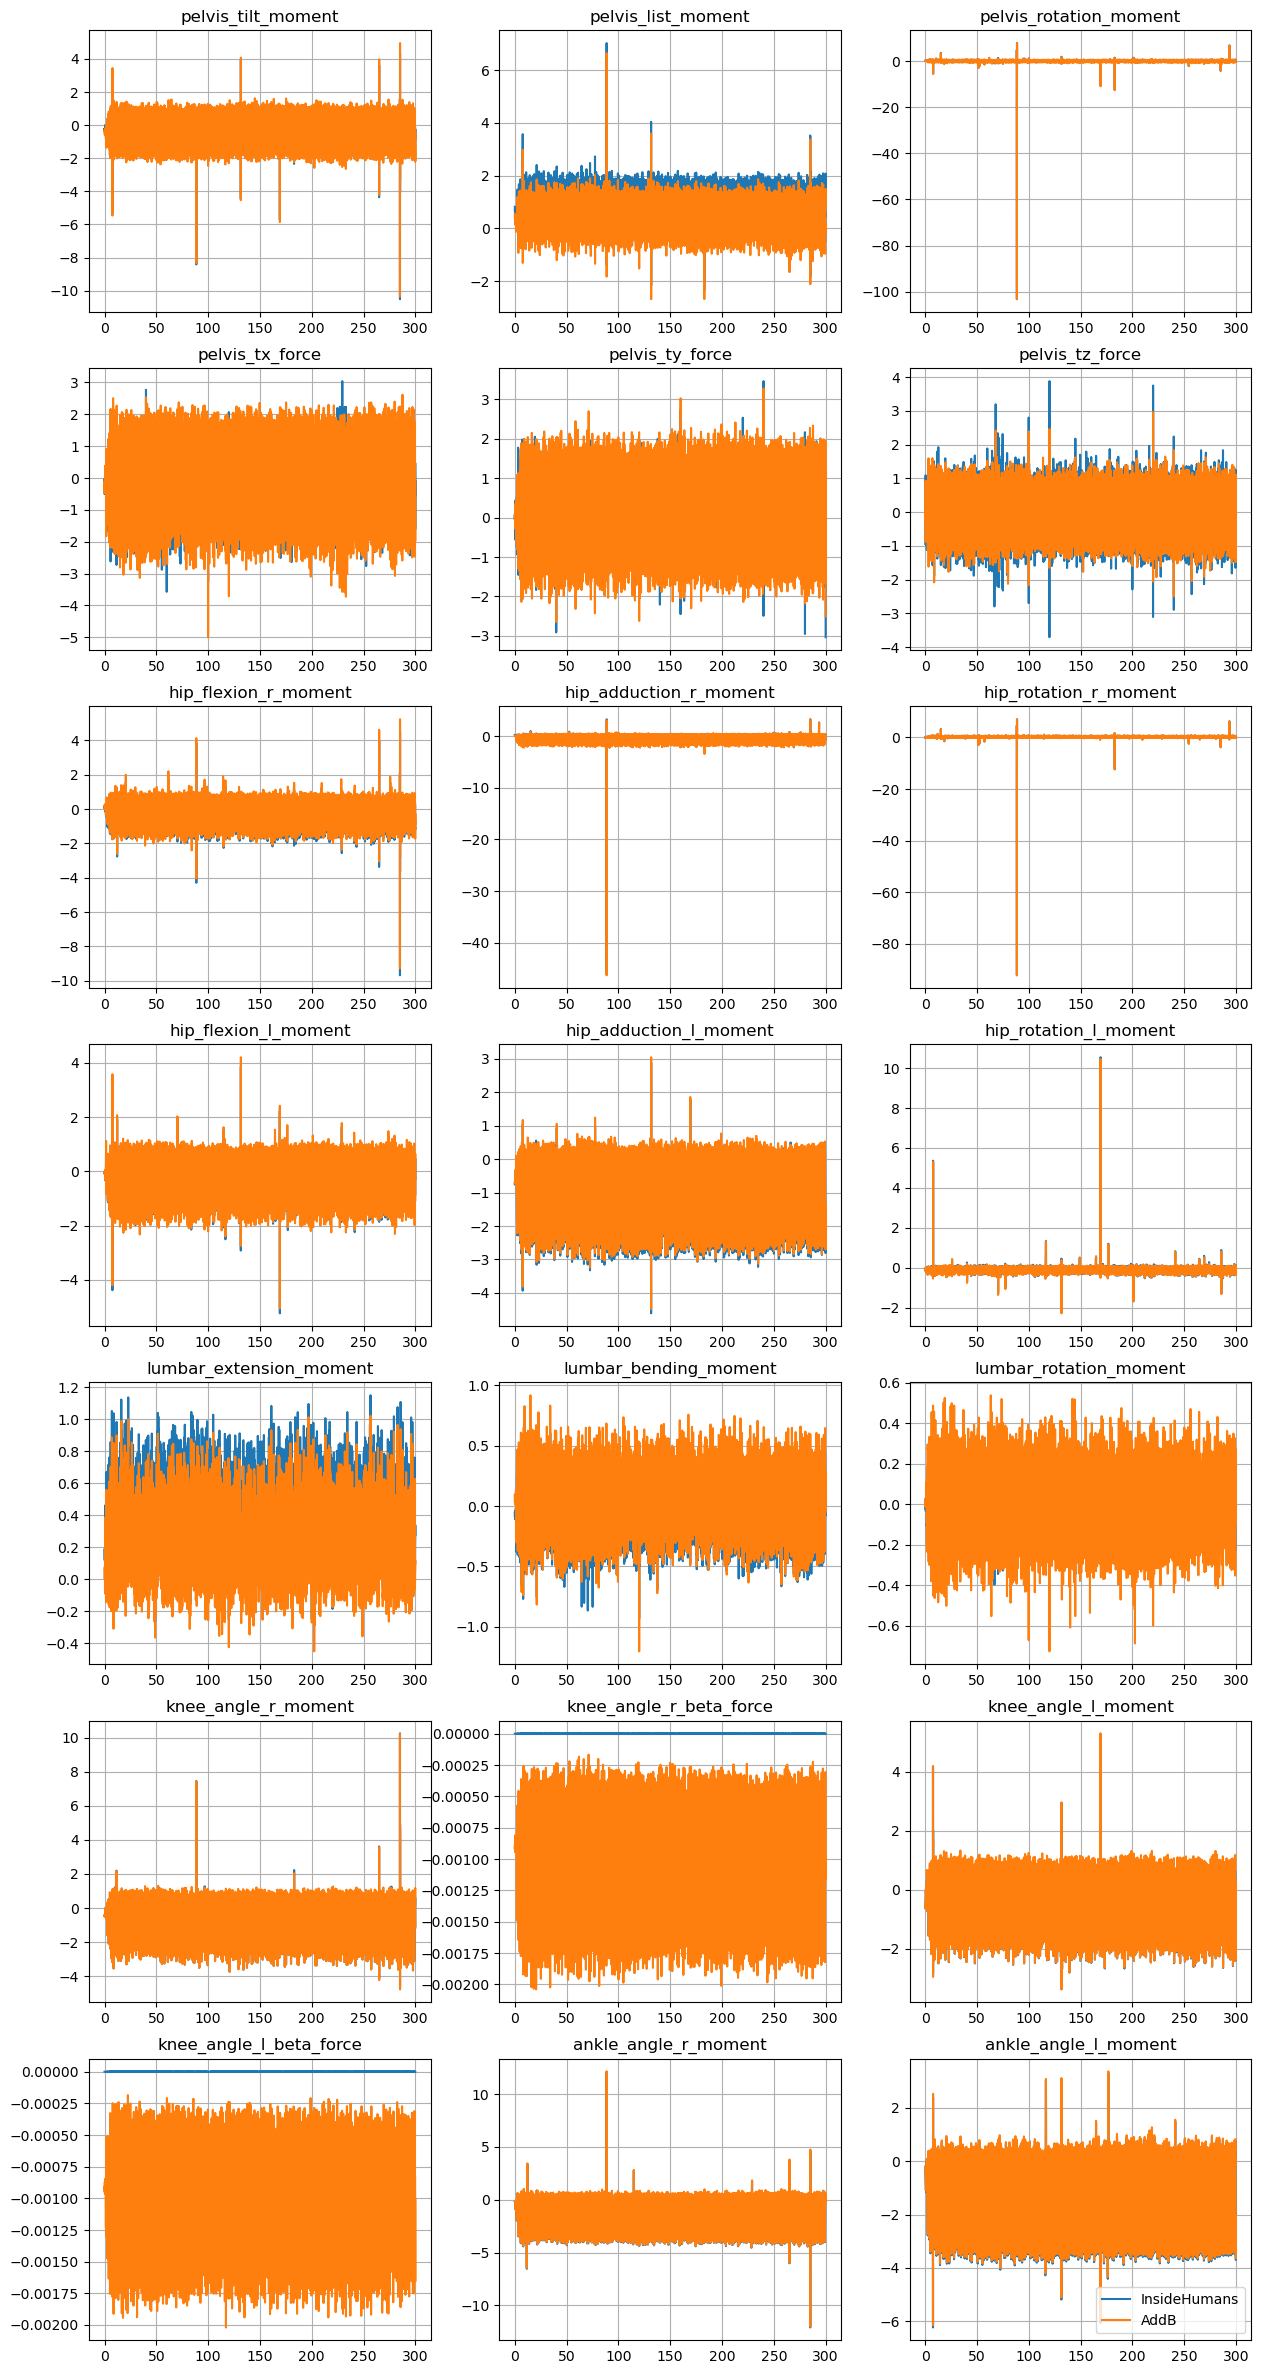

In [108]:
participant = 'P04'
trial = 1
id1 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_{name}_{model}.sto", sep='\t', skiprows=6)
id2 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_ignore_physics.sto", sep='\t', skiprows=6)
# Create a big plot 
colls =  ['pelvis_tilt_moment', 'pelvis_list_moment',
       'pelvis_rotation_moment', 'pelvis_tx_force', 'pelvis_ty_force',
       'pelvis_tz_force', 'hip_flexion_r_moment', 'hip_adduction_r_moment',
       'hip_rotation_r_moment', 'hip_flexion_l_moment',
       'hip_adduction_l_moment', 'hip_rotation_l_moment',
       'lumbar_extension_moment', 'lumbar_bending_moment',
       'lumbar_rotation_moment', 'knee_angle_r_moment',
       'knee_angle_r_beta_force', 'knee_angle_l_moment',
       'knee_angle_l_beta_force', 'ankle_angle_r_moment', 'ankle_angle_l_moment']

fig = plt.figure(figsize=(15,30))
# Plot every column
idx = 0
for col_a in colls:
    ax = fig.add_subplot(7,3,idx+1)
    start = 0
    end = 30000
    plt.plot(id1.time[start:end], id1[col_a][start:end]/mass, label='InsideHumans')
    plt.plot(id2.time[start:end], id2[col_a][start:end]/mass, label='AddB')
    ax.set_title(col_a)
    idx += 1
    plt.grid()
plt.legend()

In [94]:
norm = np.mean(np.linalg.norm([id1['pelvis_tx_force'], id1['pelvis_ty_force'], id1['pelvis_tz_force']], axis=0))

In [120]:
#ik_data = pd.read_csv(f"results/prelim/{participant.replace('P','S')}/IK/Trial{trial}.mot", sep='\t', skiprows=10)
# Gradient over each column:


df = pd.DataFrame(columns=['participant', 'trial', 'pow_type', 'value'])

for participant,mass in zip(participants, mass_list):
    for trial in [1,2,3,4,5,6]:
        if participant in ['Pü01','P03'] or (participant == 'P06' and trial == 5) or (participant == 'P01' and trial > 2):
            continue
        ik_data = pd.read_csv(f"results/{participant}/gait/addB-ignore_phys/IK/Trial{trial}.mot", sep='\t', skiprows=10)
        id1 = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_HIT_body.sto", sep='\t', skiprows=6)
        id2 = pd.read_csv(f"results/{participant}/gait/ID_results//Trial{trial}_ignore_physics.sto", sep='\t', skiprows=6)
        pow1 = np.zeros(ik_data.shape)
        pow2 = np.zeros(ik_data.shape)
        for i, col_a in enumerate(ik_data.columns):
            ik_data.loc[:,col_a] = np.gradient(ik_data[col_a]) * 100
            if col_a in ['time', 'Time', 'Frame#'] or col_a.startswith('pelvis'):
                continue
            try:
                pow1[:,i] = id1[col_a+'_moment'] * ik_data[col_a] / len(ik_data)
                pow2[:,i] = id2[col_a+'_moment'] * ik_data[col_a] / len(ik_data)  
            except:
                pow1[:,i] = id1[col_a+'_force'] * ik_data[col_a] / len(ik_data) 
                pow2[:,i] = id2[col_a+'_force'] * ik_data[col_a] / len(ik_data)
                print(col_a)
        #df.loc[len(df)] = [participant, trial, 'pos_ih', np.sum(pow1[pow1>0])/mass]
        #df.loc[len(df)] = [participant, trial, 'neg_ih', -np.sum(pow1[pow1<0])/mass]
        #df.loc[len(df)] = [participant, trial, 'pos_addb', np.sum(pow2[pow2>0])/mass]
        #df.loc[len(df)] = [participant, trial, 'neg_addb', -np.sum(pow2[pow2<0])/mass]
        df.loc[len(df)] = [participant, trial, 'pos_rel', -1+np.sum(pow2[pow2>0])/np.sum(pow1[pow1>0])]
        df.loc[len(df)] = [participant, trial, 'neg_rel', -1+np.sum(pow2[pow2<0])/np.sum(pow1[pow1<0])]
        #df.loc[len(df)] = [participant, trial, 'total_ih', np.sum(np.abs(pow1))/mass]
        #df.loc[len(df)] = [participant, trial, 'total_addb', np.sum(np.abs(pow2))/mass]
        df.loc[len(df)] = [participant, trial, 'total_rel', -1+np.sum(np.abs(pow2))/np.sum(np.abs(pow1))]
    

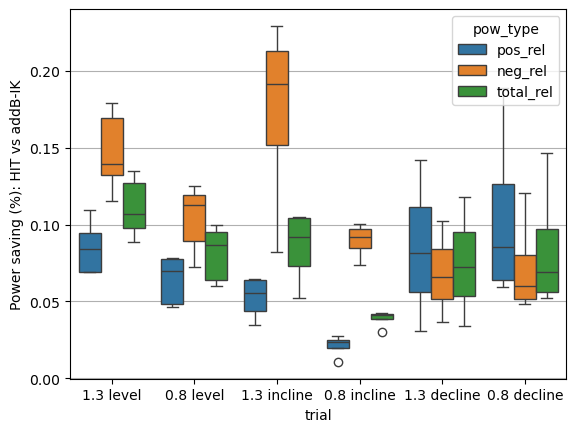

trial=1, pow_type=pos_rel: 0.09
trial=1, pow_type=neg_rel: 0.15
trial=1, pow_type=total_rel: 0.11
trial=2, pow_type=pos_rel: 0.06
trial=2, pow_type=neg_rel: 0.10
trial=2, pow_type=total_rel: 0.08
trial=3, pow_type=pos_rel: 0.05
trial=3, pow_type=neg_rel: 0.17
trial=3, pow_type=total_rel: 0.09
trial=4, pow_type=pos_rel: 0.02
trial=4, pow_type=neg_rel: 0.09
trial=4, pow_type=total_rel: 0.04
trial=5, pow_type=pos_rel: 0.08
trial=5, pow_type=neg_rel: 0.07
trial=5, pow_type=total_rel: 0.07
trial=6, pow_type=pos_rel: 0.10
trial=6, pow_type=neg_rel: 0.07
trial=6, pow_type=total_rel: 0.08
pow_type=pos_rel: 0.069
pow_type=neg_rel: 0.112
pow_type=total_rel: 0.081
trial=1: 0.114
trial=2: 0.083
trial=3: 0.104
trial=4: 0.050
trial=5: 0.076
trial=6: 0.087
Overall: 0.087


In [121]:
df2 = df.copy()
x = 'trial'
hue = 'pow_type'
sns.boxplot(df2, x=x, y='value', hue=hue)
# Y grid
plt.grid(axis='y')
# Plot the mean for every column
# Rename the xticks
plt.xticks(labels=["1.3 level", "0.8 level", "1.3 incline", "0.8 incline", "1.3 decline", "0.8 decline"], ticks=[0, 1, 2, 3, 4, 5])
plt.ylabel('Power saving (%): HIT vs addB-IK')
#plt.xlabel('Trial')
plt.show()
# print the mean for every column x and per x and hue
# Get a list of unique values in the column
for value_ in df2[x].unique():
    for hue_ in df2[hue].unique():
        print(f'{x}={value_}, {hue}={hue_}: {df2[(df2[x] == value_) & (df2[hue] == hue_)].value.mean():.2f}')
for hue_ in df2[hue].unique():
    print(f'{hue}={hue_}: {df2[df2[hue] == hue_].value.mean():.3f}')
for value_ in df2[x].unique():
    print(f'{x}={value_}: {df2[df2[x] == value_].value.mean():.3f}')
# Print the mean for every column
print(f'Overall: {df2.value.mean():.3f}')
# Print the mean for every column

In [435]:
df

,participant,trial,pow_type,value
0,P02,1,pos_ih,2.397241
1,P02,1,neg_ih,-1.917463
2,P02,1,pos_addb,2.698844
3,P02,1,neg_addb,-2.219591
4,P02,1,pos_rel,1.125813
...,...,...,...,...
67,P06,3,pos_rel,1.039868
68,P06,3,neg_rel,1.059132
69,P06,3,total_ih,6.932517
70,P06,3,total_addb,7.262580


# P01 Force plates

In [9]:
trial = 1
path = f"data/P03/gait/Trial{trial}.mot"
grf_df = pd.read_csv(path, sep='\t', skiprows=5)

4.928378277218481


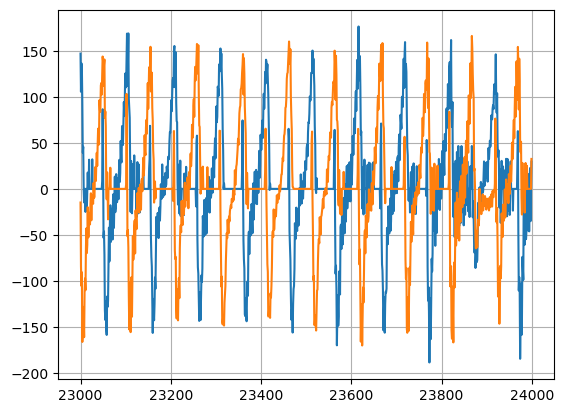

In [32]:
# rotate the force 8 percent in the z.axis
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
if trial in [1,2]:
    a = 0
else:
    a = -4.57 if trial in [5,6] else 4.57
grf_df_new = grf_df.copy()
grf_df_new['ground_force_vx'] = grf_df['ground_force_vx']*np.cos(np.deg2rad(a)) - grf_df['ground_force_vy']*np.sin(np.deg2rad(a))
grf_df_new['ground_force_vy'] = grf_df['ground_force_vx']*np.sin(np.deg2rad(a)) + grf_df['ground_force_vy']*np.cos(np.deg2rad(a))
grf_df_new['1_ground_force_vx'] = grf_df['1_ground_force_vx']*np.cos(np.deg2rad(a)) - grf_df['1_ground_force_vy']*np.sin(np.deg2rad(a))
grf_df_new['1_ground_force_vy'] = grf_df['1_ground_force_vx']*np.sin(np.deg2rad(a)) + grf_df['1_ground_force_vy']*np.cos(np.deg2rad(a))
#grf_df_new['1_ground_force_vx'] -= grf_df_new['1_ground_force_vx'].median()
#grf_df_new['ground_force_vx'] -= grf_df_new['ground_force_vx'].median()
plt.plot(grf_df_new['1_ground_force_vx'][23000:24000])
plt.plot(grf_df['ground_force_vx'][23000:24000])
print(grf_df_new['1_ground_force_vx'].mean())
plt.grid()

In [554]:
grf_df_new['ground_force_vx'][23000:24000].mean()

2.9532020737595146

In [7]:
os.getcwd()

'/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins'

In [8]:
for p in range(1,7):
    pp = f"P0{p}" 
    fold_0 = f"results/{pp}/gait/addB-ignore_phys"
    fold_1 = f"results/{pp}/gait/addB-with_phys"
    fold_2 = f"results/{pp}/gait/ID_results"
    os.makedirs(fold_0, exist_ok=True)
    os.makedirs(fold_1, exist_ok=True)
    os.makedirs(fold_2, exist_ok=True)

In [17]:
subprocess.run("which python", shell=True)

/opt/homebrew/Caskroom/miniforge/base/envs/osim_10/bin/python


CompletedProcess(args='which python', returncode=0)

In [1]:
asasd = 1

In [ ]:
hit_path = "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/P02/gait/addB-with_phys/HIT/ID"
generic_path = "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/P02/gait/addB-with_phys/generic/ID"
# for every file that ends with .sto in the HIT folder
HIT = {
    "pelvis_tx_force": [],
    "pelvis_ty_force": [],
    "pelvis_tz_force": [],
    "pelvis_tilt_moment": [],
    "pelvis_list_moment": [],
    "pelvis_rotation_moment": []
}
generic = {
    "pelvis_tx_force": [],
    "pelvis_ty_force": [],
    "pelvis_tz_force": [],
    "pelvis_tilt_moment": [],
    "pelvis_list_moment": [],
    "pelvis_rotation_moment": []
}

for file in os.listdir(hit_path):
    if file.endswith(".sto"):
        hit = pd.read_csv(os.path.join(hit_path, file), sep='\t', skiprows=10)
        for key in HIT.keys():
            HIT[key].append(np.abs(hit[key]).mean()/73.35/9.81)
for file in os.listdir(generic_path):
    if file.endswith(".sto"):
        gen = pd.read_csv(os.path.join(generic_path, file), sep='\t', skiprows=10)
        for key in generic.keys():
            generic[key].append(np.abs(gen[key]).mean()/73.35/9.81)


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'pelvis_tx_force'),
  Text(1, 0, 'pelvis_ty_force'),
  Text(2, 0, 'pelvis_tz_force'),
  Text(3, 0, 'pelvis_tilt_moment'),
  Text(4, 0, 'pelvis_list_moment'),
  Text(5, 0, 'pelvis_rotation_moment')])

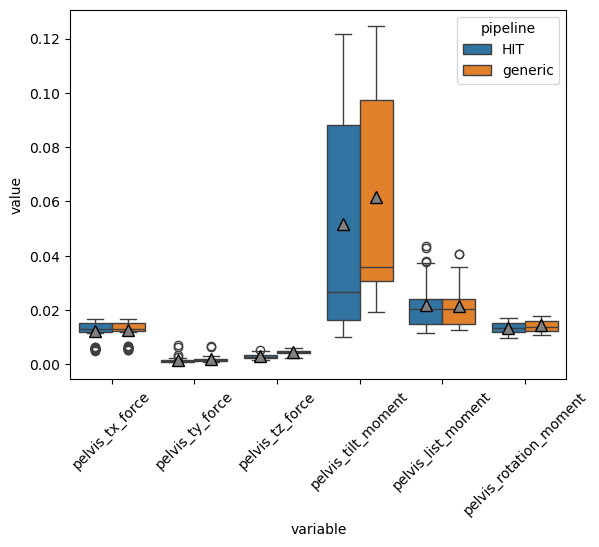

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt
# Create a dataframe
hit = pd.DataFrame(HIT)
gen = pd.DataFrame(generic)
hit['pipeline'] = 'HIT'
gen['pipeline'] = 'generic'
df = pd.concat([hit, gen])
df = df.melt(id_vars='pipeline')
sns.boxplot(x='variable', y='value', data=df, hue='pipeline', showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
plt.xticks(rotation=45)


([0], [Text(0, 0, '0')])

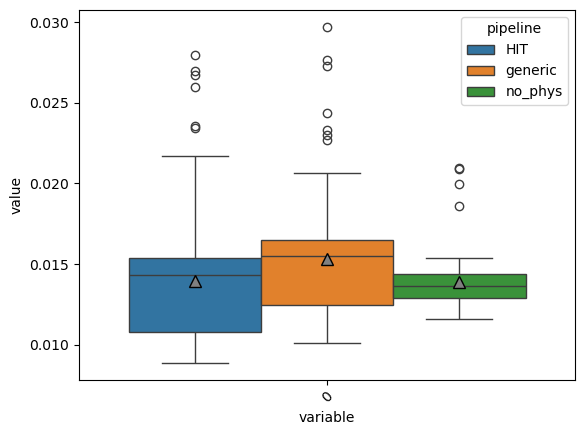

In [40]:
hit_path = "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/P02/gait/addB-with_phys/HIT/IK"
generic_path = "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/P02/gait/addB-with_phys/generic/IK"
no_phys_path = "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/results/P02/gait/addB-ignore_phys/IK"
# for every file that ends with .sto in the HIT folder
HIT = []
generic = []
no_phys = []
for file in os.listdir(hit_path):
    if file.endswith(".csv"):
        hit = pd.read_csv(os.path.join(hit_path, file))
        HIT.append(np.array(hit.iloc[:,1:]).mean())
for file in os.listdir(generic_path):
    if file.endswith(".csv"):
        gen = pd.read_csv(os.path.join(generic_path, file))
        generic.append(np.array(gen.iloc[:,1:]).mean())
for file in os.listdir(no_phys_path):
        if file.endswith(".csv"):
            no = pd.read_csv(os.path.join(no_phys_path, file))
            no_phys.append(np.array(no.iloc[:,1:]).mean())
import seaborn as sns
import matplotlib.pyplot as plt
# Create a dataframe
hit = pd.DataFrame(HIT)
gen = pd.DataFrame(generic)
no = pd.DataFrame(no_phys)
hit['pipeline'] = 'HIT'
gen['pipeline'] = 'generic'
no['pipeline'] = 'no_phys'
df = pd.concat([hit, gen, no])
df = df.melt(id_vars='pipeline')
sns.boxplot(x='variable', y='value', data=df, hue='pipeline',showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
plt.xticks(rotation=45)



In [29]:
HIT

{'pelvis_tx_force': [],
 'pelvis_ty_force': [],
 'pelvis_tz_force': [],
 'pelvis_tilt_moment': [],
 'pelvis_list_moment': [],
 'pelvis_rotation_moment': [C7      0.016329
  CLAV    0.015453
  LANK    0.012647
  LASI    0.016027
  LBHD    0.026610
  LELB    0.023044
  LFIN    0.022886
  LFRM    0.017272
  LHEE    0.016652
  LKNE    0.013041
  LPSI    0.010154
  LSHO    0.029466
  LTHI    0.017432
  LTIB    0.011813
  LTOE    0.013272
  LUPA    0.011581
  LWRA    0.020059
  LWRB    0.011332
  RANK    0.016294
  RASI    0.017798
  RBAK    0.011461
  RBHD    0.014909
  RELB    0.020151
  RFHD    0.022039
  RFIN    0.017972
  RFRM    0.011511
  RHEE    0.013767
  RKNE    0.011999
  RPSI    0.014588
  RSHO    0.032718
  RTHI    0.017828
  RTIB    0.012009
  RTOE    0.017317
  RUPA    0.008978
  RWRA    0.016766
  RWRB    0.007697
  STRN    0.009568
  T10     0.005996
  LFHD    0.029214
  dtype: float64,
  C7      0.026312
  CLAV    0.021165
  LANK    0.005629
  LASI    0.007497
  LBHD    0.0

In [46]:
df

,pipeline,variable,value
0,HIT,pelvis_tx_force,0.016680
1,HIT,pelvis_tx_force,0.012275
2,HIT,pelvis_tx_force,0.005774
3,HIT,pelvis_tx_force,0.012826
4,HIT,pelvis_tx_force,0.013004
...,...,...,...
649,generic,pelvis_rotation_moment,0.016862
650,generic,pelvis_rotation_moment,0.015883
651,generic,pelvis_rotation_moment,0.012835
652,generic,pelvis_rotation_moment,0.015572


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'pelvis_tx_force'),
  Text(1, 0, 'pelvis_ty_force'),
  Text(2, 0, 'pelvis_tz_force'),
  Text(3, 0, 'pelvis_tilt_moment'),
  Text(4, 0, 'pelvis_list_moment'),
  Text(5, 0, 'pelvis_rotation_moment')])

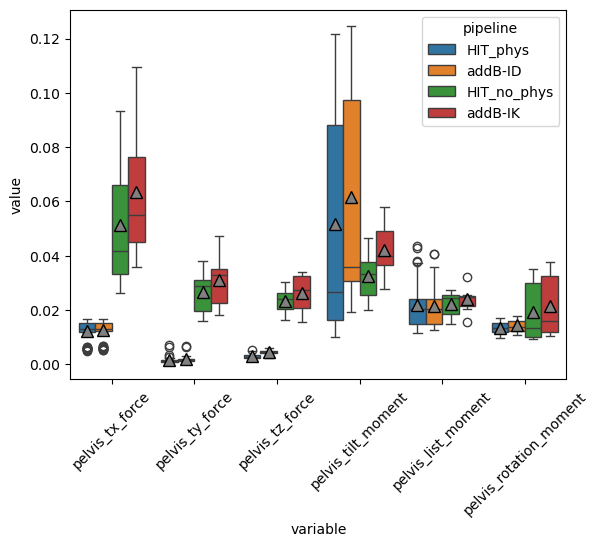

In [ ]:
rd2 = result_df.copy()
rd2 = rd2[rd2.participant == 'P02'][['dimension','value','pipeline']]
# rename dimension to variable
rd2 = rd2.rename(columns={'dimension':'variable'})
rd2.loc[rd2.pipeline == 'HIT','pipeline'] = 'HIT_no_phys'
df.loc[df.pipeline == 'HIT','pipeline'] = 'HIT_phys'
df.loc[df.pipeline == 'generic','pipeline'] = 'addB-ID'
df = pd.concat([df, rd2])
df = df[df.variable != 'f_norm']
df = df[df.variable != 'm_norm']
sns.boxplot(x='variable', y='value', data=df, hue='pipeline',showmeans = True,meanprops={'marker':'^','markerfacecolor':'grey','markeredgecolor':'black','markersize':'8'})
plt.xticks(rotation=45)

In [64]:
for pipeline in ['HIT_phys','HIT_no_phys','addB-ID','addB-IK']:
    print(f"{pipeline}: {df[df.pipeline == pipeline].value.mean()}")


HIT_phys: 0.017225476161655522
HIT_no_phys: 0.029262212610903362
addB-ID: 0.019356947844382716
addB-IK: 0.034684783404893456


In [36]:

name = "generic_male"
model_c = f"--model generic"
scan_c = f"--pipeline HIT"
input_path = f"--input_path results/generic_male/bodyhull"
output_path = f"--output_path results/generic_male/{name}"
mass_c = f"--mass 86"
gender_c = f"--gender=male"
hull_c = f"--hull=loose"
extra_commans = f"--debug=True --use_skel=True"
skel_c = "_w_skel"
# 
command = f"python src/bodyscan/estimate_bsip.py {model_c} {scan_c} {input_path} {output_path} {mass_c} {gender_c} {hull_c} {extra_commans}"
subprocess.run(command, shell=True)

opensim_model = f"data/resources/unscaled_generic_P06_no_CLAV.osim"
opensim_model = opensim_utils.get_model(opensim_model)
hull_bsip = pd.read_pickle(f"results/generic_male/generic_male/HIT_generic_loose_w_skel.pkl")
new_hull_bsip, osim_model = opensim_utils.hull_bsip_to_opensim(hull_bsip, opensim_model, extra_shoe_weight = 0, arms_from_hull=False) # Arms from hull would be ideal
opensim_utils.save_opensim_model(osim_model, f"results/generic_male/smpl_male_P06_no_CLAV.osim")

opensim_model = f"data/resources/unscaled_generic.osim"
opensim_model = opensim_utils.get_model(opensim_model)
hull_bsip = pd.read_pickle(f"results/generic_female/generic_male/HIT_generic_loose_w_skel.pkl")
new_hull_bsip, osim_model = opensim_utils.hull_bsip_to_opensim(hull_bsip, opensim_model, extra_shoe_weight=0, arms_from_hull=False) # Arms from hull would be ideal, please check
opensim_utils.save_opensim_model(osim_model, f"results/generic_male/smpl_male.osim")

True
Meshes of result: dict_keys(['all', 'AT', 'BT', 'LT', 'skel']) MOI: dict_keys(['all', 'AT', 'BT', 'LT', 'skel'])
Mesh name: all
Volume: (new | old | diff) [L]: 82.80 | 82.80 | -0.00
Mesh name: AT
Volume: (new | old | diff) [L]: 25.51 | 25.51 | -0.00
Mesh name: BT
Volume: (new | old | diff) [L]: 3.65 | 3.65 | 0.00
Mesh name: LT
Volume: (new | old | diff) [L]: 52.80 | 52.80 | -0.00
Mesh name: skel
Volume: (new | old | diff) [L]: 7.57 | 7.71 | -0.14
Total mass: [86.32333156], Adjusting to 86.0
BSIPs estimated and saved to  {'results/generic_male/generic_male/HIT_generic_loose_w_skel.pkl'}
[info] Updating Model file from 40000 to latest format...
[info] Loaded model FullBodyModel_MuscleActuatedLowerLimb_TorqueActuatedUpperBody from file data/resources/unscaled_generic_P06_no_CLAV.osim
[warning] Couldn't find file 'r_pelvis.vtp'.
[warning] Couldn't find file 'l_pelvis.vtp'.
[warning] Couldn't find file 'sacrum.vtp'.
[warning] Couldn't find file 'r_femur.vtp'.
[warning] Couldn't find fi

FileNotFoundError: [Errno 2] No such file or directory: 'results/generic_female/generic_male/HIT_generic_loose_w_skel.pkl'

In [ ]:
name = "generic_female"
model_c = f"--model generic"
scan_c = f"--pipeline HIT"
input_path = f"--input_path results/generic_female/bodyhull"
output_path = f"--output_path results/generic_female/{name}"
mass_c = f"--mass 70"
gender_c = f"--gender=female"
hull_c = f"--hull=loose"
extra_commans = f"--debug=True --use_skel=True"
skel_c = "_w_skel"
# 
command = f"python src/bodyscan/estimate_bsip.py {model_c} {scan_c} {input_path} {output_path} {mass_c} {gender_c} {hull_c} {extra_commans}"
subprocess.run(command, shell=True)

opensim_model = f"data/resources/unscaled_generic_P06_no_CLAV.osim"
opensim_model = opensim_utils.get_model(opensim_model)
hull_bsip = pd.read_pickle(f"results/generic_female/generic_female/HIT_generic_loose_w_skel.pkl")
new_hull_bsip, osim_model = opensim_utils.hull_bsip_to_opensim(hull_bsip, opensim_model, extra_shoe_weight = 0, arms_from_hull=False) # Arms from hull would be ideal
opensim_utils.save_opensim_model(osim_model, f"results/generic_female/smpl_female_P06_no_CLAV.osim")

opensim_model = f"data/resources/unscaled_generic.osim"
opensim_model = opensim_utils.get_model(opensim_model)
hull_bsip = pd.read_pickle(f"results/generic_female/generic_female/HIT_generic_loose_w_skel.pkl")
new_hull_bsip, osim_model = opensim_utils.hull_bsip_to_opensim(hull_bsip, opensim_model, extra_shoe_weight=0, arms_from_hull=False) # Arms from hull would be ideal, please check
opensim_utils.save_opensim_model(osim_model, f"results/generic_female/smpl_female.osim")

True
Meshes of result: dict_keys(['all', 'AT', 'BT', 'LT', 'skel']) MOI: dict_keys(['all', 'AT', 'BT', 'LT', 'skel'])
Mesh name: all
Volume: (new | old | diff) [L]: -1154088141085501.50 | -1163811366666666.75 | 9723225581165.28
Mesh name: AT
Volume: (new | old | diff) [L]: 28.05 | 27.79 | 0.26
Mesh name: BT
Volume: (new | old | diff) [L]: 1.99 | 1.99 | 0.00
Mesh name: LT
Volume: (new | old | diff) [L]: 38.28 | 38.28 | -0.00
Mesh name: skel
Volume: (new | old | diff) [L]: 6.10 | 6.22 | -0.12
Could not calculate inertia for  all ['AT', 'LT', 'skel']


Traceback (most recent call last):
  File "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/src/bodyscan/estimate_bsip.py", line 213, in <module>
    main()
  File "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/src/bodyscan/estimate_bsip.py", line 181, in main
    bsips = bsip_utils.estimate_bsip(result_meshes, body_orientations, skel_result['joints'], args)
  File "/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins/src/bodyscan/bsip_utils.py", line 92, in estimate_bsip
    mesh['inertia'] *= default_densities[args.pipeline][mesh_name]
KeyError: 'inertia'


[info] Updating Model file from 40000 to latest format...
[info] Loaded model FullBodyModel_MuscleActuatedLowerLimb_TorqueActuatedUpperBody from file data/resources/unscaled_generic_P06_no_CLAV.osim
[warning] Couldn't find file 'r_pelvis.vtp'.
[warning] Couldn't find file 'l_pelvis.vtp'.
[warning] Couldn't find file 'sacrum.vtp'.
[warning] Couldn't find file 'r_femur.vtp'.
[warning] Couldn't find file 'r_tibia.vtp'.
[warning] Couldn't find file 'r_fibula.vtp'.
[warning] Couldn't find file 'r_patella.vtp'.
[warning] Couldn't find file 'r_talus.vtp'.
[warning] Couldn't find file 'r_foot.vtp'.
[warning] Couldn't find file 'r_bofoot.vtp'.
[warning] Couldn't find file 'l_femur.vtp'.
[warning] Couldn't find file 'l_tibia.vtp'.
[warning] Couldn't find file 'l_fibula.vtp'.
[warning] Couldn't find file 'l_patella.vtp'.
[warning] Couldn't find file 'l_talus.vtp'.
[warning] Couldn't find file 'l_foot.vtp'.
[warning] Couldn't find file 'l_bofoot.vtp'.
[warning] Couldn't find file 'hat_spine.vtp'.


In [ ]:
for trial in range(1,7):
            if (participant == 'P01' and trial > 2) or (participant == 'P06' and trial == 5):
                continue
            opensim_utils.save_opensim_model(osim_model, f"results/{participant}/bodyhull/osim_models/{name}_{model}{skel_c}.osim")
            c0 = "python src/opensim/inverse_dynamics.py"
            c1 = f"--ik_path=results/{participant}/gait/addB-ignore_phys/IK/Trial{trial}.mot"
            c2 = f"--osim_file="+glob_path(f"results/{participant}/bodyhull/osim_models/{name}_{model}{skel_c}.osim")
            c3 = f"--output_file=results/{participant}/gait/ID_results/Trial{trial}_{name}_{model}.sto"
            c4 = f"--mot_path=data/{participant}/gait/Trial{trial}.mot --lowpass_f=15"

            subprocess.run(f"{c0} {c1.replace(f'Trial{trial}.mot','')} --concat_ik=True", shell=True)
            subprocess.run(f"{c0} {c1} {c2} {c3} {c4} > /dev/null 2>&1", shell=True)

            # Load the result file 
            res = pd.read_csv(f"results/{participant}/gait/ID_results/Trial{trial}_{name}_{model}.sto", sep='\t', skiprows=6)
            print(f"Participant: {participant}, Pipeline: {pipeline}, MAE-Y: {res['pelvis_ty_force'].abs().mean()}")
        
            # Finally, run standard ID
            c2 = f"--osim_file=results/{participant}/gait/addB-ignore_phys/Models/match_markers_but_ignore_physics.osim"
            c3 = f"--output_file=results/{participant}/gait/ID_results/Trial{trial}_ignore_physics.sto"
            subprocess.run(f"{c0} {c1} {c2} {c3} {c4} > /dev/null 2>&1", shell=True)

In [64]:
### Create SMPL-generic models
participants = ['P02','P04','P05','P06']
mass_list = [73.35,89.36,87.63,44.91]
gender_list = ['female','male','male','male']

# I guess this is accurate, but hard to find in opensim
joint_to_body_mapping = {
    "pelvis": "hip_r",
    "femur_r": "walker_knee_r",
    "tibia_r": "ankle_r",
    "patella_r": "patellofemoral_r",
    "talus_r": "subtalar_r",
    "calcn_r": "mtp_r",
    "toes_r": "mtp_r",
    "femur_l": "hip_l",
    "tibia_l": "walker_knee_l",
    "patella_l": "patellofemoral_l",
    "talus_l": "ankle_l",
    "calcn_l": "subtalar_l",
    "toes_l": "mtp_l",
    "torso": "acromial_r",
    "humerus_r": "elbow_r",
    "ulna_r": "radioulnar_r",
    "radius_r": "radius_hand_r",
    "hand_r": "radius_hand_r",
    "humerus_l": "elbow_l",
    "ulna_l": "radioulnar_l",
    "radius_l": "radius_hand_l",
    "hand_l": "radius_hand_l"
}

import src.opensim.opensim_utils as opensim_utils   
import opensim
for p, mass, gender in zip(participants,mass_list,gender_list):
    #load the generic model
    generic_smpl_model = f"results/generic_{gender}/opensim/smpl_{gender}_generic.osim"
    addB_result_model = f"results/{p}/gait/addB-ignore_phys/Models/match_markers_but_ignore_physics.osim"

    #load the generic model
    generic_model = opensim_utils.get_model(generic_smpl_model)
    addB_result_model = opensim_utils.get_model(addB_result_model)

    bodys_smpl = generic_model.getBodySet()
    bodys_res = addB_result_model.getBodySet()

    joints_smpl = generic_model.getJointSet()
    joints_res = addB_result_model.getJointSet()
    
    joint_scale_factors = {}
    for i in range(joints_smpl.getSize()):
        joint_s = joints_smpl.get(i)
        joint_res = joints_res.get(i)
        # Scale location in parent frame
        translation = joint_s.get_frames(0).get_translation()
        t_s = np.linalg.norm(np.array([translation.get(0), translation.get(1), translation.get(2)]))

        t_r = joint_res.get_frames(0).get_translation()
        t_r = np.linalg.norm(np.array([t_r.get(0), t_r.get(1), t_r.get(2)]))

        joint_scale_factors[joint_s.getName()] = t_r/t_s

    # Check the complete mass
    mass_s = []
    mass_r = []
    for i in range(bodys_smpl.getSize()):
        body_s = bodys_smpl.get(i)
        body_res = bodys_res.get(i)
        mass_s.append(body_s.getMass()*joint_scale_factors[joint_to_body_mapping[body_s.getName()]])
        mass_r.append(body_res.getMass())

    mass_s = np.array(mass_s)
    mass_r = np.array(mass_r)
    # Enforce that the target mass adds up
    extra_scale = np.sum(mass_r)/np.sum(mass_s)
    for key in joint_scale_factors.keys():
        joint_scale_factors[key] *= extra_scale

    for i in range(bodys_smpl.getSize()):
        body_s = bodys_smpl.get(i)
        body_res = bodys_res.get(i)
        
        scale_factor = joint_scale_factors[joint_to_body_mapping[body_s.getName()]]
        # Scale mass # pow 3
        mass = body_s.getMass() * scale_factor
        body_res.setMass(mass)
        # Scale inertia # pow 5, because mass is scaled by pow 3 and radius by pow 2
        inertia = opensim_utils.to_numpy3_3(body_s.get_inertia()) * scale_factor**2

        body_res.setInertia(opensim.Inertia(
            inertia[0,0], inertia[1,1], inertia[2,2],
            inertia[0,1], inertia[0,2], inertia[1,2]
        ))

        # Scale com # pow 1
        com = opensim_utils.to_numpy3(body_s.getMassCenter()) * scale_factor
        body_res.setMassCenter(opensim.Vec3(com[0], com[1], com[2]))
    

    save_path = f"results/{p}/gait/ID_results/SMPL_generic_scale.osim"
    opensim_utils.save_opensim_model(addB_result_model, save_path)#

    for trial in range(1,7):
        if (p == 'P01' and trial > 2) or (p == 'P06' and trial == 5):
            continue
        c0 = "python src/opensim/inverse_dynamics.py"
        c1 = f"--ik_path=results/{p}/gait/addB-ignore_phys/IK/Trial{trial}.mot"
        c2 = f"--osim_file="+glob_path(f"results/{p}/gait/ID_results/SMPL_generic_scale.osim")
        c3 = f"--output_file=results/{p}/gait/ID_results/Trial{trial}_{name}_{model}.sto"
        c4 = f"--mot_path=data/{p}/gait/Trial{trial}.mot --lowpass_f=15"

        subprocess.run(f"{c0} {c1.replace(f'Trial{trial}.mot','')} --concat_ik=True", shell=True)
        subprocess.run(f"{c0} {c1} {c2} {c3} {c4} > /dev/null 2>&1", shell=True)

        # Load the result file 
    

[info] Loaded model FullBodyModel_MuscleActuatedLowerLimb_TorqueActuatedUpperBody from file results/generic_female/opensim/smpl_female_generic.osim
[warning] Couldn't find file 'r_pelvis.vtp'.
[warning] Couldn't find file 'l_pelvis.vtp'.
[warning] Couldn't find file 'sacrum.vtp'.
[warning] Couldn't find file 'r_femur.vtp'.
[warning] Couldn't find file 'r_tibia.vtp'.
[warning] Couldn't find file 'r_fibula.vtp'.
[warning] Couldn't find file 'r_patella.vtp'.
[warning] Couldn't find file 'r_talus.vtp'.
[warning] Couldn't find file 'r_foot.vtp'.
[warning] Couldn't find file 'r_bofoot.vtp'.
[warning] Couldn't find file 'l_femur.vtp'.
[warning] Couldn't find file 'l_tibia.vtp'.
[warning] Couldn't find file 'l_fibula.vtp'.
[warning] Couldn't find file 'l_patella.vtp'.
[warning] Couldn't find file 'l_talus.vtp'.
[warning] Couldn't find file 'l_foot.vtp'.
[warning] Couldn't find file 'l_bofoot.vtp'.
[warning] Couldn't find file 'hat_spine.vtp'.
[warning] Couldn't find file 'hat_jaw.vtp'.
[warnin

/var/folders/zp/1cs5lqq978n6gd_m465gfm840000gn/T/ipykernel_28136/1605051645.py:60: RuntimeWarning: invalid value encountered in double_scalars
  joint_scale_factors[joint_s.getName()] = t_r/t_s


Trials concatenated and saved to results/P02/gait/addB-ignore_phys/IK/. Call this function with a specific trial to run ID
Trials concatenated and saved to results/P02/gait/addB-ignore_phys/IK/. Call this function with a specific trial to run ID
Trials concatenated and saved to results/P02/gait/addB-ignore_phys/IK/. Call this function with a specific trial to run ID
Trials concatenated and saved to results/P02/gait/addB-ignore_phys/IK/. Call this function with a specific trial to run ID
Trials concatenated and saved to results/P02/gait/addB-ignore_phys/IK/. Call this function with a specific trial to run ID
Trials concatenated and saved to results/P02/gait/addB-ignore_phys/IK/. Call this function with a specific trial to run ID
[info] Loaded model FullBodyModel_MuscleActuatedLowerLimb_TorqueActuatedUpperBody from file results/generic_male/opensim/smpl_male_generic.osim
[warning] Couldn't find file 'r_pelvis.vtp'.
[warning] Couldn't find file 'l_pelvis.vtp'.
[warning] Couldn't find file

In [61]:
os.getcwd()

'/Users/markusgambietz/PhD/01_Python_Projects/mrigait_empkins'

In [49]:
print([bodys_smpl.get(i).getName() for i in range(bodys_smpl.getSize())])

['pelvis', 'femur_r', 'tibia_r', 'patella_r', 'talus_r', 'calcn_r', 'toes_r', 'femur_l', 'tibia_l', 'patella_l', 'talus_l', 'calcn_l', 'toes_l', 'torso', 'humerus_r', 'ulna_r', 'radius_r', 'hand_r', 'humerus_l', 'ulna_l', 'radius_l', 'hand_l']


In [ ]:
['pelvis', 'femur_r', 'tibia_r', 'patella_r', 'talus_r', 'calcn_r', 'toes_r', 'femur_l', 'tibia_l', 'patella_l', 'talus_l', 'calcn_l', 'toes_l', 'torso', 'humerus_r', 'ulna_r', 'radius_r', 'hand_r', 'humerus_l', 'ulna_l', 'radius_l', 'hand_l']
{'ground_pelvis': nan,
 'hip_r': 0.8916048051109583,
 'walker_knee_r': 0.8024052562911436,
 'patellofemoral_r': 0.8024052562911436,
 'ankle_r': 0.8628886749044684,
 'subtalar_r': 0.7953692156466643,
 'mtp_r': 0.951477507678958,
 'hip_l': 0.8916048051109583,
 'walker_knee_l': 0.8024052562911436,
 'patellofemoral_l': 0.8024052562911436,
 'ankle_l': 0.8628886749044684,
 'subtalar_l': 0.7953692156466643,
 'mtp_l': 0.951477507678958,
 'back': 0.8632126629611862,
 'acromial_r': 0.7550697422734094,
 'elbow_r': 0.8191924896673518,
 'radioulnar_r': 0.8110130027264287,
 'radius_hand_r': 0.8208676654375942,
 'acromial_l': 0.7550697422734094,
 'elbow_l': 0.8191924896673518,
 'radioulnar_l': 0.8110130027264287,
 'radius_hand_l': 0.8208676654375942}
joint_to_body_mapping = {
    "pelvis": "hip_r",
    "femur_r": "walker_knee_r",
    "tibia_r": "ankle_r",
    "patella_r": "patellofemoral_r",
    "talus_r": "subtalar_r",
    "calcn_r": "mtp_r",
    "toes_r": "mtp_r",
    "femur_l": "hip_l",
    "tibia_l": "walker_knee_l",
    "patella_l": "patellofemoral_l",
    "talus_l": "ankle_l",
    "calcn_l": "subtalar_l",
    "toes_l": "mtp_l",
    "torso": "acromial_r",
    "humerus_r": "elbow_r",
    "ulna_r": "radioulnar_r",
    "radius_r": "radius_hand_r",
    "hand_r": "radius_hand_r",
    "humerus_l": "elbow_l",
    "ulna_l": "radioulnar_l",
    "radius_l": "radius_hand_l",
    "hand_l": "radius_hand_l"
}


In [23]:
import pandas as pd
sipp_bsip = pd.read_pickle('results/generic_male/bsip/HIT_generic_loose_w_skel.pkl')
opensim_bsip = opensim_utils.get_bsip_dataframe(opensim_utils.get_model('data/resources/unscaled_generic.osim'))

[info] Updating Model file from 40000 to latest format...
[info] Loaded model FullBodyModel_MuscleActuatedLowerLimb_TorqueActuatedUpperBody from file data/resources/unscaled_generic.osim
[warning] Couldn't find file 'r_pelvis.vtp'.
[warning] Couldn't find file 'l_pelvis.vtp'.
[warning] Couldn't find file 'sacrum.vtp'.
[warning] Couldn't find file 'r_femur.vtp'.
[warning] Couldn't find file 'r_tibia.vtp'.
[warning] Couldn't find file 'r_fibula.vtp'.
[warning] Couldn't find file 'r_patella.vtp'.
[warning] Couldn't find file 'r_talus.vtp'.
[warning] Couldn't find file 'r_foot.vtp'.
[warning] Couldn't find file 'r_bofoot.vtp'.
[warning] Couldn't find file 'l_femur.vtp'.
[warning] Couldn't find file 'l_tibia.vtp'.
[warning] Couldn't find file 'l_fibula.vtp'.
[warning] Couldn't find file 'l_patella.vtp'.
[warning] Couldn't find file 'l_talus.vtp'.
[warning] Couldn't find file 'l_foot.vtp'.
[warning] Couldn't find file 'l_bofoot.vtp'.
[warning] Couldn't find file 'hat_spine.vtp'.
[warning] Co

In [24]:
sipp_bsip

,segment,mass,mass_center,inertia
0,toes_r,[0.046629365882750434],"[0.0010445629698141007, 0.0006926119706590917,...","[[8.501164164111059e-06, 2.112449847876548e-07..."
1,calcn_r,0.755904,"[0.015495399069960359, 0.003302562908523539, 0...","[[0.0024749808593250025, 0.0002355011650013486..."
2,tibia_r,3.362515,"[-0.0016570069780418863, -0.16959267585029394,...","[[0.04646412394773325, 0.0013620992226666935, ..."
3,femur_r,10.033345,"[-0.0200317901863219, -0.15845788897726817, -0...","[[0.16266227576971973, 0.016735647739854084, -..."
4,pelvis,11.088411,"[-0.009671291748552274, -0.019219607711022237,...","[[0.08241412055316923, 0.00044395851463191336,..."
5,lumbar_body,37.973652,"[0.0008986122606986763, 0.19643996532780603, 0...","[[1.399334083567399, 0.005289625564717598, -0...."
6,humerus_r,2.469773,"[-0.11853106153099939, -0.022986663834363076, ...","[[0.004005581774244564, -0.0013679169949585004..."
7,ulna_r,1.290979,"[-0.11121222961036305, 0.0034940412397458025, ...","[[0.0009077362330626278, -8.001859586632108e-0..."
8,hand_r,[0.40240802343358106],"[-0.06490390929873485, -0.00987064077778037, -...","[[0.00033213470055028666, -0.00016671818324802..."
9,toes_l,[0.06780769880651086],"[0.011590027192714347, 0.0040953638581817595, ...","[[1.794906095503058e-05, -2.035269615862407e-0..."


In [40]:
np.diag(opensim_bsip.inertia.iloc[14]), np.diag(opensim_bsip.inertia.iloc[18])

(array([0.011946, 0.004121, 0.013409]), array([0.011946, 0.004121, 0.013409]))

In [41]:
np.diag(sipp_bsip.inertia.iloc[6]), np.diag(sipp_bsip.inertia.iloc[13])

(array([0.00400558, 0.01714052, 0.01764564]),
 array([0.00379327, 0.01681218, 0.01732795]))

In [46]:
# Rotate a vector 90° along the x-axis
import numpy as np
from scipy.spatial.transform import Rotation as R

r = R.from_euler('xyz', [0,0,-np.pi/2], degrees=False)
display(sipp_bsip.mass_center.iloc[6].copy() @ r.as_matrix())
display(np.diag(r.as_matrix()@sipp_bsip.inertia.iloc[6].copy() @ r.as_matrix().T))

r = R.from_euler('xyz', [0,0,np.pi/2], degrees=False)
display(sipp_bsip.mass_center.iloc[13].copy() @ r.as_matrix())
display((r.as_matrix() @ sipp_bsip.inertia.iloc[13].copy()))

array([ 0.02298666, -0.11853106, -0.02867476])

array([0.01714052, 0.00400558, 0.01764564])

array([-0.02013968, -0.11769523, -0.02102106])

array([[-0.00099087, -0.01681218,  0.00019974],
       [ 0.00379327,  0.00099087, -0.00016225],
       [-0.00016225, -0.00019974,  0.01732795]])

In [47]:
sipp_bsip

,segment,mass,mass_center,inertia
0,toes_r,[0.046629365882750434],"[0.0010445629698141007, 0.0006926119706590917,...","[[8.501164164111059e-06, 2.112449847876548e-07..."
1,calcn_r,0.755904,"[0.015495399069960359, 0.003302562908523539, 0...","[[0.0024749808593250025, 0.0002355011650013486..."
2,tibia_r,3.362515,"[-0.0016570069780418863, -0.16959267585029394,...","[[0.04646412394773325, 0.0013620992226666935, ..."
3,femur_r,10.033345,"[-0.0200317901863219, -0.15845788897726817, -0...","[[0.16266227576971973, 0.016735647739854084, -..."
4,pelvis,11.088411,"[-0.009671291748552274, -0.019219607711022237,...","[[0.08241412055316923, 0.00044395851463191336,..."
5,lumbar_body,37.973652,"[0.0008986122606986763, 0.19643996532780603, 0...","[[1.399334083567399, 0.005289625564717598, -0...."
6,humerus_r,2.469773,"[-0.11853106153099939, -0.022986663834363076, ...","[[0.004005581774244564, -0.0013679169949585004..."
7,ulna_r,1.290979,"[-0.11121222961036305, 0.0034940412397458025, ...","[[0.0009077362330626278, -8.001859586632108e-0..."
8,hand_r,[0.40240802343358106],"[-0.06490390929873485, -0.00987064077778037, -...","[[0.00033213470055028666, -0.00016671818324802..."
9,toes_l,[0.06780769880651086],"[0.011590027192714347, 0.0040953638581817595, ...","[[1.794906095503058e-05, -2.035269615862407e-0..."


In [52]:
a = np.load("results/P01/bodyhull/smpl_fit/musc/loose_skel/musc_layer_ignored_segments.npz", allow_pickle=True)

In [53]:
a['pose'].shape

(1, 46)